# Mecanismo de Laplace

El mecanismo de Laplace añade ruido aleatorio a una consulta agregada (conteo, media, suma) sobre un conjunto de datos, de forma que el resultado no permite saber con certeza si un individuo concreto estaba o no en los datos, garantizando formalmente $(\epsilon, \delta)$-privacidad diferencial.

Siendo D y D' dos bases de datos, S un conjunto de posibles resultados, $\epsilon$ el nivel de privacidad(cuanto menor sea, más restrictiva es la garantía), $\delta$ la desviación respecto a la garantía multiplicativa(si es nula, es una privacidad diferencial pura). Un mecanismo aleatorio M satisface $(\epsilon, \delta)$-privacidad si:

$p(M(D)\in S) \leq e^{\epsilon}P(M(D')\in S)+\delta$


La sensibilidad global expresa la máxima diferencia que podemos encontrar al aplicar la
función a dos bases de datos que difieren en un solo elemento.

$\Delta f=\max_{D\sim D'} \left\lVert f(D) - f(D') \right\rVert_{1}$

Siendo $b=\frac{\Delta f}{\epsilon}$ la escala que controla la dispersión de ruido:

$p(x)=\frac{1}{2b}e^{-\frac{\lvert x \rvert}{b}}$

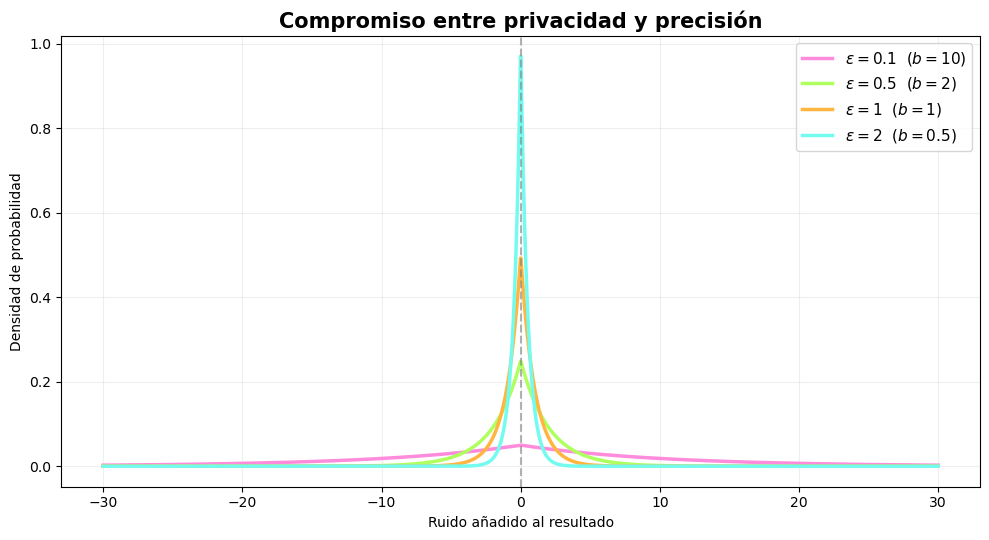

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros
sensibilidad = 1 # Es 1 ya que son individuos y la consulta es un conteo
epsilons = [0.1, 0.5, 1.0, 2.0]

# Valores posibles del ruido
x = np.linspace(-30, 30, 2000)

# Colores para distinguir las distribuciones
colores = ["#FF8BDC", "#AFFF5F", "#FFB640", "#73FBF0"]

plt.figure(figsize=(10, 5.5))

for epsilon, color in zip(epsilons, colores):

    # Escala de Laplace de ruido
    b = sensibilidad / epsilon

    # Función de densidad de Laplace
    densidad = (1 / (2 * b)) * np.exp(-np.abs(x) / b)

    plt.plot(
        x,
        densidad,
        linewidth=2.5,
        color=color,
        label=fr"$\varepsilon={epsilon:g}$  ($b={b:g}$)"
    )

# Línea vertical en ruido = 0
plt.axvline(0, color="gray", linestyle="--", alpha=0.6)

plt.title(
    "Compromiso entre privacidad y precisión",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Ruido añadido al resultado")
plt.ylabel("Densidad de probabilidad")

plt.legend(fontsize=11)
plt.grid(alpha=0.2)

plt.tight_layout()

# Guardar la gráfica en formato PNG y PDF 
plt.savefig("epsilon.png", dpi=300)
plt.savefig("epsilon.pdf", bbox_inches="tight")

plt.show()

Como podemos observar, cuanto mayor es el nivel de privacidad, mayor es el ruido añadido y la densidad de probabilidad es menor y hay menos resultados acercándose al eje 0 cercanos al resultado original.

El compromiso entre privacidad y precisión se resume en encontrar el equilibrio entre cuánto queremos proteger los datos y cuánta precisión queremos en los resultados.